In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
classification_report,
ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [4]:
import pandas as pd

df = pd.read_csv('/content/ai4i2020.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.head

<bound method NDFrame.head of         UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
0         1     M14860    M                298.1  ...    0    0    0    0
1         2     L47181    L                298.2  ...    0    0    0    0
2         3     L47182    L                298.1  ...    0    0    0    0
3         4     L47183    L                298.2  ...    0    0    0    0
4         5     L47184    L                298.2  ...    0    0    0    0
...     ...        ...  ...                  ...  ...  ...  ...  ...  ...
9995   9996     M24855    M                298.8  ...    0    0    0    0
9996   9997     H39410    H                298.9  ...    0    0    0    0
9997   9998     M24857    M                299.0  ...    0    0    0    0
9998   9999     H39412    H                299.0  ...    0    0    0    0
9999  10000     M24859    M                299.0  ...    0    0    0    0

[10000 rows x 14 columns]>

In [6]:
df.tail

<bound method NDFrame.tail of         UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
0         1     M14860    M                298.1  ...    0    0    0    0
1         2     L47181    L                298.2  ...    0    0    0    0
2         3     L47182    L                298.1  ...    0    0    0    0
3         4     L47183    L                298.2  ...    0    0    0    0
4         5     L47184    L                298.2  ...    0    0    0    0
...     ...        ...  ...                  ...  ...  ...  ...  ...  ...
9995   9996     M24855    M                298.8  ...    0    0    0    0
9996   9997     H39410    H                298.9  ...    0    0    0    0
9997   9998     M24857    M                299.0  ...    0    0    0    0
9998   9999     H39412    H                299.0  ...    0    0    0    0
9999  10000     M24859    M                299.0  ...    0    0    0    0

[10000 rows x 14 columns]>

In [7]:
df.shape

(10000, 14)

In [8]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [9]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [12]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [14]:
y=df["Machine failure"]

In [15]:
categorical_feature=["Type"]

numerical_feature=["Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]

In [16]:
X_train,X_test,y_train,y_test=train_test_split(df,y,test_size=0.2,random_state=42,stratify=y)

print("training sample:",X_train.shape[0])
print("testing sample:",X_test.shape[0])

training sample: 8000
testing sample: 2000


In [17]:
preprocessor=ColumnTransformer(transformers=[
    ('num',StandardScaler(),numerical_feature),
    ('cat',OneHotEncoder(),categorical_feature)
])

In [19]:
linear_svm=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('classifier',SVC(kernel='linear'))
    ]
)
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [20]:
y_pred_linear=linear_svm.predict(X_test)

In [22]:
accuracy_linear=accuracy_score(y_test,y_pred_linear)
precision_linear=precision_score(y_test,y_pred_linear,zero_division=0)
recall_linear=recall_score(y_test,y_pred_linear,zero_division=0)
f1_linear=f1_score(y_test,y_pred_linear,zero_division=0)

print("Accuracy:",accuracy_linear)
print("Precision:",precision_linear)
print("Recall:",recall_linear)
print("F1 Score:",f1_linear)


Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [23]:
print(classification_report(y_test,y_pred_linear,target_names=["No Failure","failure"],
   zero_division=0

))


              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



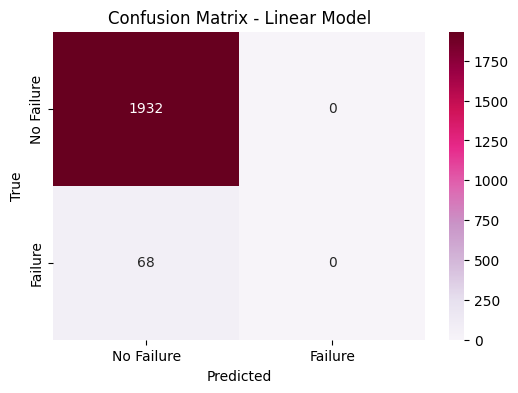

In [29]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="PuRd",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Linear Model")
plt.show()

In [30]:
rbf_svm=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('classifier',SVC(kernel='rbf'))
    ]
)
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [36]:
y_pred_rbf = rbf_svm.predict(X_test)

In [37]:
y_pred_rbf = rbf_svm.predict(X_test)

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Step 1: Predict using the RBF SVM model
y_pred_rbf = rbf_svm.predict(X_test)

# Step 2: Calculate performance metrics
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

# Step 3: Display results
print("RBF SVM Model Performance")
print("-------------------------")
print("Accuracy :", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall   :", recall_rbf)
print("F1 Score :", f1_rbf)

RBF SVM Model Performance
-------------------------
Accuracy : 0.9715
Precision: 0.9230769230769231
Recall   : 0.17647058823529413
F1 Score : 0.2962962962962963


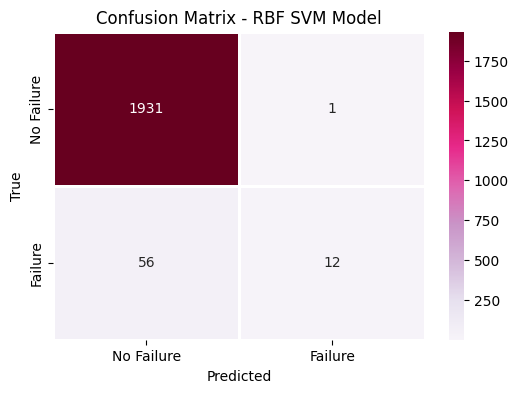

In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="PuRd",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"],
    linewidths=1,
    linecolor="white"
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - RBF SVM Model")
plt.show()

In [41]:
comparison = pd.DataFrame({
    "kernel": ["Linear", "RBF"],
    "accuracy": [accuracy_linear, accuracy_rbf],
    "precision": [precision_linear, precision_rbf],
    "recall": [recall_linear, recall_rbf],
    "f1_score": [f1_linear, f1_rbf]
})

comparison

,kernel,accuracy,precision,recall,f1_score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9715,0.923077,0.176471,0.296296


In [43]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel='rbf'))
    ]
)

In [46]:
param_grid = [
    {"classifier__kernel": ["rbf"],
     "classifier__C": [0.1, 1, 10, 100],
     "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1]}
]

In [47]:
param_grid = [
    {"classifier__kernel": ["linear"],
     "classifier__C": [0.1, 1, 10, 100]},

    {"classifier__kernel": ["rbf"],
     "classifier__C": [0.1, 1, 10, 100],
     "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1]}
]

In [48]:
Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [54]:
final_comparison=pd.DataFrame({
    "kernel": ["Linear", "RBF"],
    "accuracy": [accuracy_linear, accuracy_rbf],
    "precision": [precision_linear, precision_rbf],
    "recall": [recall_linear, recall_rbf],
    "f1_score": [f1_linear, f1_rbf]
})

final_comparison

,kernel,accuracy,precision,recall,f1_score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9715,0.923077,0.176471,0.296296
